# Multi-Region Feature Ranking Analysis
This notebook analyzes the baseline Random Forest feature importance artifacts across biogeographic regions:
1. **Per-Region Top-N Importance Plots** grouped and colored by domain category.
2. **Cross-Region Commonality Analysis** (Upset / Overlap heatmap & Jaccard similarity of top features).
3. **Domain Category Distribution** across regions to evaluate spectral vs. topographic dependency.

In [4]:
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

artifacts_dir = Path('data/feature_selection_artifacts')
TOP_N = 20

# Locate all available region ranking JSONs
ranking_files = sorted(artifacts_dir.glob('*_ranked_features.json'))
print(f"Found {len(ranking_files)} region artifacts: {[f.stem.replace('_ranked_features', '') for f in ranking_files]}")

region_data = {}
for f in ranking_files:
    with open(f, 'r') as fp:
        content = json.load(fp)
        region_name = content.get('region', f.stem.replace('_ranked_features', ''))
        region_data[region_name] = content

regions = list(region_data.keys())
print(f"Loaded regions: {regions}")

Found 7 region artifacts: ['DES', 'HIM', 'ICR', 'IGP', 'NEI', 'PEN', 'WGR']
Loaded regions: ['DES', 'HIM', 'ICR', 'IGP', 'NEI', 'PEN', 'WGR']


In [5]:
# Categorization rule to segment features by domain sensor / thematic type
def categorize_feature(name: str) -> str:
    topo = {'elevation', 'slope', 'aspect_cos', 'aspect_sin', 'hand'}
    coords = {'lat', 'lon'}
    sma = {'gv', 'npv', 'soil', 'shade', 'ndfi'}
    bands = {'blue', 'green', 'red', 'nir', 'swir1', 'swir2', 'tir'}
    tasseled_cap = {'tcb', 'tcg', 'tcw'}
    indices = {'ndvi', 'evi2', 'mndwi', 'ndmi', 'bci', 'ibi'}
    landcover_masks = {'BareEarth', 'StableWater', 'TransientWater'}

    base_token = name.split('_')[0]
    if name in topo:
        return 'Topography / Hydrology'
    if name in coords:
        return 'Coordinates'
    if base_token in sma:
        return 'Spectral Unmixing (SMA)'
    if base_token in bands:
        return 'Surface Reflectance Bands'
    if base_token in indices:
        return 'Spectral Indices'
    if base_token in tasseled_cap:
        return 'Tasseled Cap'
    if name in landcover_masks:
        return 'Ancillary Masks'
    return 'Other'

CATEGORY_PALETTE = {
    'Topography / Hydrology': '#8c564b',
    'Coordinates': '#7f7f7f',
    'Spectral Indices': '#2ca02c',
    'Surface Reflectance Bands': '#1f77b4',
    'Spectral Unmixing (SMA)': '#ff7f0e',
    'Tasseled Cap': '#9467bd',
    'Ancillary Masks': '#17becf',
    'Other': '#d62728'
}

## 1. Top-N Ranked Features per Region (Colored by Category)

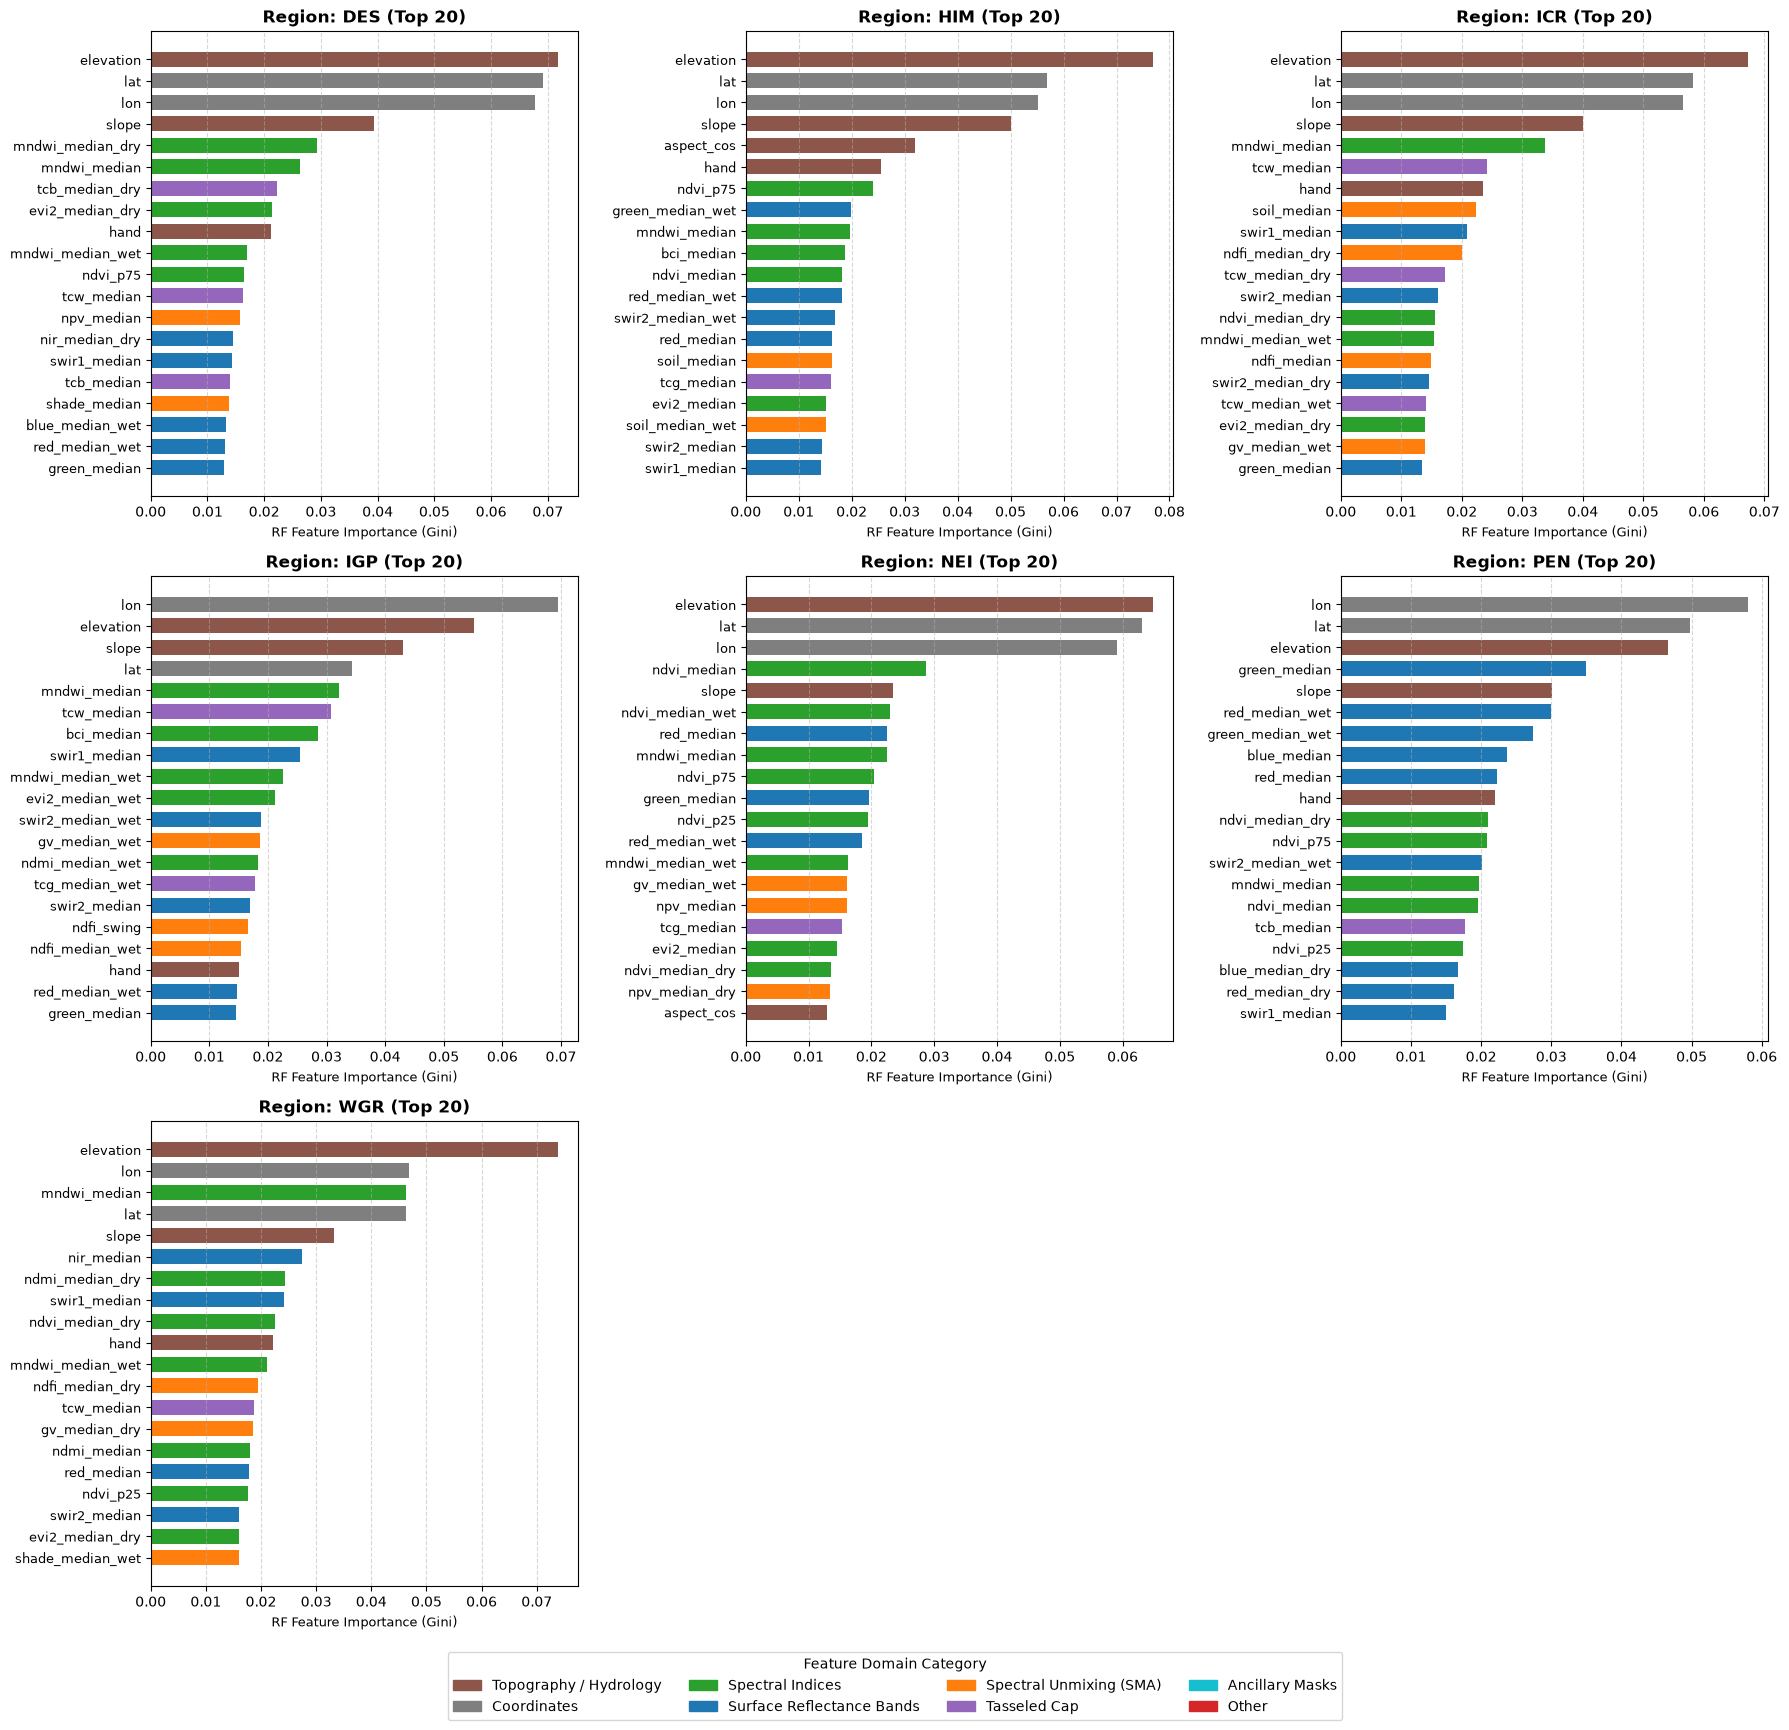

In [6]:
num_regions = len(regions)
cols = 3
rows = math.ceil(num_regions / cols)

fig, axes = plt.subplots(rows, cols, figsize=(18, rows * 5.5), squeeze=False)
axes = axes.flatten()

for idx, reg in enumerate(regions):
    ax = axes[idx]
    rf_data = region_data[reg]
    ranked_feats = rf_data['ranked_features'][:TOP_N]
    importances = [rf_data['feature_importances'][f] for f in ranked_feats]
    categories = [categorize_feature(f) for f in ranked_feats]
    colors = [CATEGORY_PALETTE.get(c, '#333333') for c in categories]

    # Horizontal bar plot (topmost feature at the top)
    y_pos = np.arange(len(ranked_feats))
    ax.barh(y_pos, importances[::-1], color=colors[::-1], edgecolor='none', height=0.7)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(ranked_feats[::-1], fontsize=9)
    ax.set_title(f"Region: {reg} (Top {TOP_N})", fontsize=12, fontweight='bold')
    ax.set_xlabel('RF Feature Importance (Gini)', fontsize=9)
    ax.grid(axis='x', linestyle='--', alpha=0.5)

# Hide unused axes
for extra_idx in range(num_regions, len(axes)):
    fig.delaxes(axes[extra_idx])

# Shared category legend
legend_handles = [
    mpatches.Patch(color=col, label=cat)
    for cat, col in CATEGORY_PALETTE.items()
]
fig.legend(
    handles=legend_handles,
    loc='lower center',
    ncol=4,
    bbox_to_anchor=(0.5, -0.05),
    frameon=True,
    title="Feature Domain Category",
    fontsize=10
)

plt.tight_layout()
plt.show()

## 2. Cross-Region Top-N Comparison & Overlap Matrix

Features in Top 20 across ALL 7 regions (5): ['elevation', 'lat', 'lon', 'mndwi_median', 'slope']


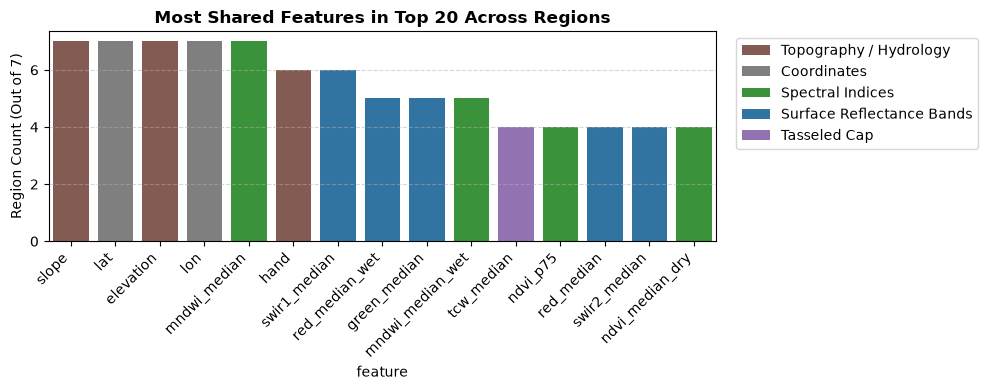

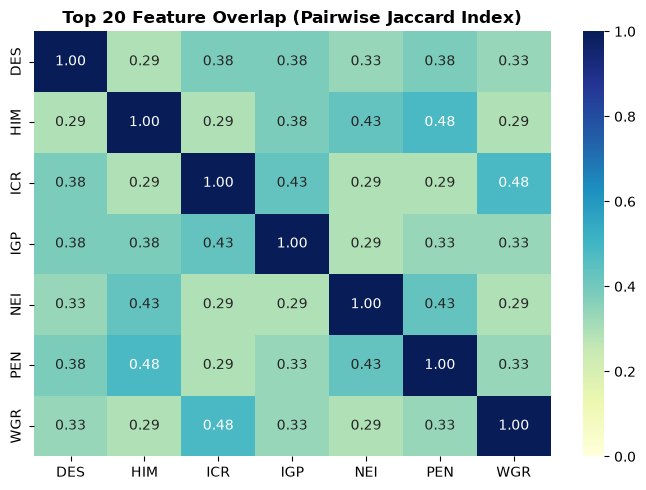

In [7]:
# Top-N sets per region
top_n_sets = {reg: set(region_data[reg]['ranked_features'][:TOP_N]) for reg in regions}

# Strict intersection across all regions
universal_top = set.intersection(*top_n_sets.values())
print(f"Features in Top {TOP_N} across ALL {len(regions)} regions ({len(universal_top)}): {sorted(universal_top)}")

# Frequency table of features appearing in Top-N across groups
all_top_features = [feat for s in top_n_sets.values() for feat in s]
freq_series = pd.Series(all_top_features).value_counts()
freq_df = pd.DataFrame({
    'feature': freq_series.index,
    'region_count': freq_series.values,
    'category': [categorize_feature(f) for f in freq_series.index]
})

plt.figure(figsize=(10, 4))
sns.barplot(data=freq_df.head(15), x='feature', y='region_count', hue='category', palette=CATEGORY_PALETTE, dodge=False)
plt.title(f"Most Shared Features in Top {TOP_N} Across Regions", fontweight='bold')
plt.ylabel(f"Region Count (Out of {len(regions)})")
plt.xticks(rotation=45, ha='right')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Pairwise Jaccard overlap heatmap
jaccard_mat = pd.DataFrame(index=regions, columns=regions, dtype=float)
for r1 in regions:
    for r2 in regions:
        s1, s2 = top_n_sets[r1], top_n_sets[r2]
        jaccard_mat.loc[r1, r2] = len(s1 & s2) / len(s1 | s2)

plt.figure(figsize=(7, 5))
sns.heatmap(jaccard_mat.astype(float), annot=True, fmt=".2f", cmap='YlGnBu', vmin=0, vmax=1)
plt.title(f'Top {TOP_N} Feature Overlap (Pairwise Jaccard Index)', fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Category Proportion Breakdown across Regions

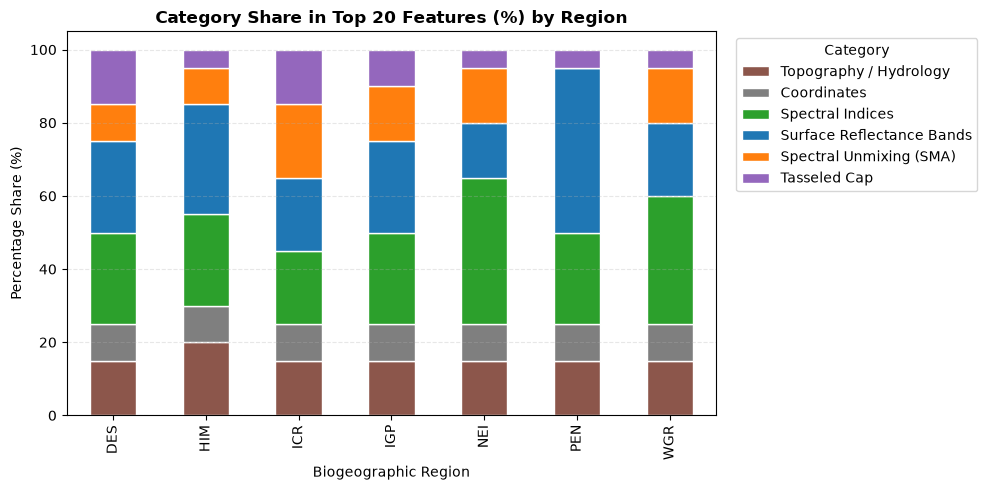

In [8]:
cat_rows = []
for reg in regions:
    top_feats = region_data[reg]['ranked_features'][:TOP_N]
    for f in top_feats:
        cat_rows.append({'region': reg, 'feature': f, 'category': categorize_feature(f)})

cat_df = pd.DataFrame(cat_rows)
cross_tab = pd.crosstab(cat_df['region'], cat_df['category'], normalize='index') * 100

# Ensure columns align with defined palette
palette_ordered_cols = [c for c in CATEGORY_PALETTE.keys() if c in cross_tab.columns]
cross_tab = cross_tab[palette_ordered_cols]

ax = cross_tab.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5),
    color=[CATEGORY_PALETTE[c] for c in cross_tab.columns],
    edgecolor='white'
)
plt.title(f'Category Share in Top {TOP_N} Features (%) by Region', fontweight='bold')
plt.ylabel('Percentage Share (%)')
plt.xlabel('Biogeographic Region')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Category')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()